### Full dynesty run + visualization Pipeline)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from HItargets_utils import *
import fspiderman as sp
from dynesty import utils as dyfunc, plotting as dyplot
from hyperillumination_phasecurve_utils import *
from simple_bias_analysis import *
import time

In [10]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from target data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

# 0.3 seems like a reasonable assumption for TOI-2431b
A_B_true = 0.3

INSOL_TRUTH = "hyperillum"  # insolation model used to generate the simulated truth

# ASSUMPTION (!): Model for band-integrated albedo in the observing band
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.)

# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

n_bins = 27 # number of bins in one orbit
sigma_1min = rms_1min(planet, instrument)
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm") # detection error [ppm per minute] for the chosen instrument
# sigma_1min = rms_1min(planet, "MIRI/LRS", lrs_range)
n_orbits = 3 # number of orbits observed (3 orbits has been done)

seed=42

PandExo inputs for TOI-2431 b  [instrument=MIRI LRS]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.534        R_earth          <- pl_rade
    rs_rsun    = 0.651        R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.7475       h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Number Too High?': 'All g

In [3]:
l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

# context for simulating data functions
cfg = FittingConfig(planet=planet, stellar_grid=stellar_grid, filter_path=lrs_path, l1=l1, l2=l2, A_=A_model,
                    sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

print(f"period = {planet.period*24*60:.1f} min -> {n_bins} bins of {planet.period*24*60/n_bins:.1f} min")
print(f"1-sigma per bin (over all orbits) = {cfg.sigma_bin:.1f} ppm")

no stellar models provided, using blackbody approximation
period = 403.7 min -> 27 bins of 15.0 min
1-sigma per bin (over all orbits) = 23.1 ppm


### 1. Simulated Data

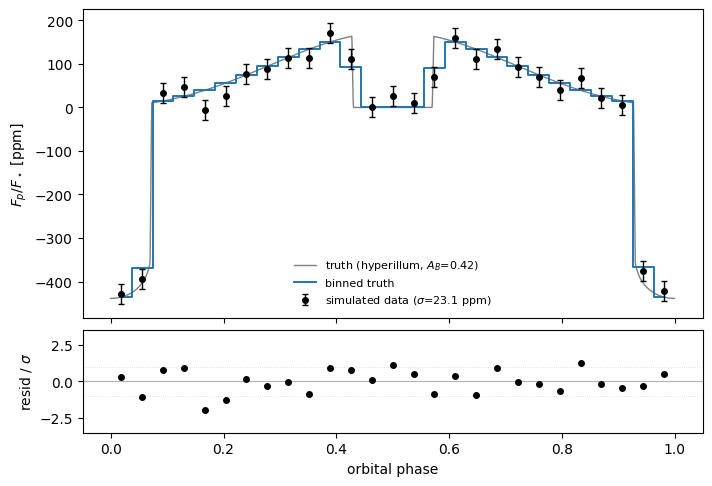

sigma_bin: 23.07 ppm  (bin width 14.95 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.63
residual mean / sigma (~0): -0.03


In [4]:
# SIMULATED OBSERVATION
data = simulate_data(cfg, A_B_true, insolation_model=INSOL_TRUTH)

### 2. Likelihood `GaussianLogL`

This is the object dynesty wants as `loglike`: a picklable, module-level callable`theta -> lnL`, where `theta` is ordered by `names` (that ordering is also the column order of`res.samples`). Anything `model_pcurve` needs that is *not* sampled goes into `fixed`.$$\ln\mathcal{L}(\theta) = -\tfrac{1}{2}\sum_i\left[\left(\frac{y_i-m_i(\theta)}{s_i}\right)^2 + \ln\left(2\pi s_i^2\right)\right]$$The $\ln(2\pi s^2)$ term is $\theta$-independent and cancels in Bayes factors on identical data,but keeping it makes $\ln Z$ a properly normalised evidence.Two geometry-only caches are built automatically and are **bit-identical** to recomputing:`reflected_unit` (reflected light is exactly linear in $A$) and the insolation map($T(A_B)=T(A_B{=}0)\,(1-A_B)^{1/4}$ exactly, so the order-64 penumbra integral is A_B-independent).Each is dropped as soon as a parameter it depends on is sampled — `logl.cache_used` says which survived.

In [5]:
N_JOBS = -1 # use every core

# ParameterSet holds everything about the free parameters: it fixes the column order of theta and of res.samples, supplies the dynesty ptform, carries the LaTeX labels, and hands evidence_bruteforce the same prior box the sampler used. Defined once here, reused by every cell below.
A_B_BOUNDS, OFF_BOUNDS = (0.0, 0.8), (-50., 50.)     # uniform priors; only used to build pset
pset = ParameterSet((Parameter("A_B",    Uniform(*A_B_BOUNDS), r"$A_B$"),
                     Parameter("offset", Uniform(*OFF_BOUNDS), "offset [ppm]")))

A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)
A_fine, O_fine = pset.grid("A_B", 201), pset.grid("offset", 401)
base  = dict(A_B=A_B_true, offset=0.) # the injected truth
COLOR = {"naive": "C0", "hyperillum": "C3"}

# LogLikelihoods. Same data, same priors -> the two lnZ are comparable
logls = {m: GaussianLogL.from_pset(cfg, data, m, pset) for m in ("naive", "hyperillum")}

print(pset.ndim, "free parameters:", pset.names, "  bounds:", pset.bounds)
for L in logls.values():
    th = theta_of(L, base)
    L(th)  # warm up
    t0 = time.perf_counter(); val = L(th); dt = time.perf_counter() - t0
    print(f"{L!r}")
    print(f"   lnL(truth) = {val:9.2f}   chi2 = {L.chi2(th):6.1f} / {cfg.n_bins} bins   {dt*1e3:6.0f} ms/call  ->  {dt*1e4/60:.0f} min per 1e4 calls (serial)")

2 free parameters: ('A_B', 'offset')   bounds: [(0.0, 0.8), (-50.0, 50.0)]
GaussianLogL(naive, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))
   lnL(truth) =   -118.33   chi2 =   17.6 / 27 bins       90 ms/call  ->  15 min per 1e4 calls (serial)
GaussianLogL(hyperillum, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))
   lnL(truth) =   -117.89   chi2 =   16.7 / 27 bins      132 ms/call  ->  22 min per 1e4 calls (serial)


#### 2.1 1-D slices

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$, so the dotted lines at$-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels.Scanning `offset` is free — it enters additively, so the whole slice comes from one forward model.

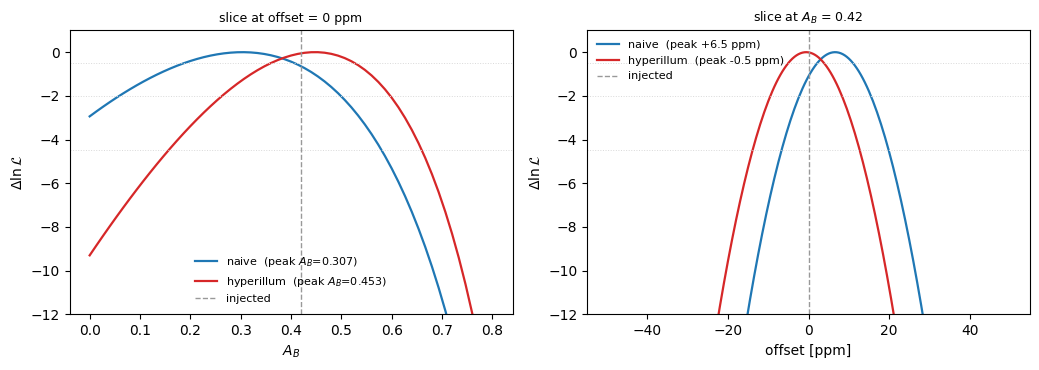

In [6]:
fig, (axA, axO) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for name, L in logls.items():
    sA = logl_slice(L, "A_B",    A_grid, base, n_jobs=N_JOBS)   # 61 forward models per insolation model
    sO = logl_slice(L, "offset", O_grid, base, n_jobs=N_JOBS)   # free: the offset is additive
    axA.plot(A_grid, sA - sA.max(), color=COLOR[name], lw=1.6, label=f"{name}  (peak $A_B$={A_grid[sA.argmax()]:.3f})")
    axO.plot(O_grid, sO - sO.max(), color=COLOR[name], lw=1.6, label=f"{name}  (peak {O_grid[sO.argmax()]:+.1f} ppm)")

for ax, truth, xl in ((axA, A_B_true, "$A_B$"), (axO, 0., "offset [ppm]")):
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(truth, color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(xl); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(-12, 1.); ax.legend(frameon=False, fontsize=8)
axA.set_title(f"slice at offset = {base['offset']:g} ppm", fontsize=9)
axO.set_title(f"slice at $A_B$ = {base['A_B']:g}", fontsize=9)
plt.tight_layout(); plt.show()

#### 2.2 2-D map - the shape dynesty has to sample
With a **uniform** prior, $\exp(\ln\mathcal{L})$ over this box *is* the un-normalised posterior, so this map is a direct preview of the corner plot the sampler should return. Contours are the 2-parameter $1/2/3\sigma$ levels ($\Delta\ln\mathcal{L}=-1.15,-3.09,-5.91$).

naive: 61 forward models in 0.5 s   (caches: ('refl', 'insol'))
grid MAP: A_B = 0.4133, offset = +6.50 ppm, lnL = -117.23
hyperillum: 61 forward models in 0.3 s   (caches: ('refl', 'insol'))
grid MAP: A_B = 0.4667, offset = +1.50 ppm, lnL = -117.81
naive: logL_max = -117.227
hyperillum: logL_max = -117.812


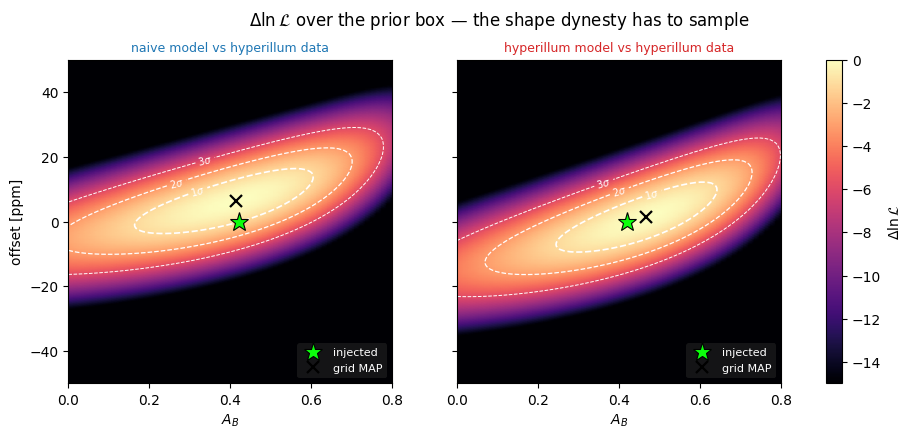

In [7]:
# TODO: add rp_rs vs A_B plot

# Same layout as 2.1: both insolation models side by side in one figure, on a shared colour scale.
lnL_maps = {}
for name, L in logls.items():
    t0 = time.perf_counter()
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name}: {len(A_grid)} forward models in {time.perf_counter()-t0:.1f} s   (caches: {L.cache_used})")
    print(f"grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharex=True, sharey=True)
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, 0., "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those now mean naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    print(f"{name}: logL_max = {lnL.max():.3f}")
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: both panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty has to sample", y=1.0)
plt.show()

## 3. Nested sampling

In [8]:
# pfrac=0 -> all sampling effort on lnZ (for Bayes' factor)
tag = f"{cfg.planet.name}_{instrument}_{A_model.label}_AB{A_B_true:g}".replace("/", "-").replace(" ", "")
scfg = {m: SamplerConfig(dynamic=True, pfrac=0.0, nlive=500, nlive_batch=250, maxbatch=10, dlogz=0.01, nprocs=8, seed=seed,
                         outfile=f"dynesty_results/{tag}_{m}_seed{seed}.pkl") for m in ("naive", "hyperillum")}

fits = {name: run_nested_fit(L, pset, scfg[name]) for name, L in logls.items()}   # dynesty Results in fits[name].results

4257it [08:29,  8.36it/s, batch: 0 | bound: 7 | nc: 1 | ncall: 20583 | eff(%): 20.682 | loglstar: -117.227 | logz: -120.121 +/-  0.062 | dlogz:  0.000 >  0.010]                           



naive: lnZ = -120.1213 +/- 0.0648,  20583 calls, 8.7 min (25 ms/call)
   CONVERGED | stop 0.648, 0/10 batches, ESS 1936
   saved -> HI PhaseCurve Fitting/dynesty_results/K2-141b_MIRI-LRS_fixedA0.1_AB0.42_naive_seed42.pkl


4292it [06:03, 11.82it/s, batch: 0 | bound: 7 | nc: 1 | ncall: 20556 | eff(%): 20.880 | loglstar: -117.812 | logz: -120.778 +/-  0.063 | dlogz:  0.000 >  0.010]                            


hyperillum: lnZ = -120.7776 +/- 0.0658,  20556 calls, 6.2 min (18 ms/call)
   CONVERGED | stop 0.658, 0/10 batches, ESS 1948
   saved -> HI PhaseCurve Fitting/dynesty_results/K2-141b_MIRI-LRS_fixedA0.1_AB0.42_hyperillum_seed42.pkl


### 3.1 Evidence & Bayes factor
With two free parameters the evidence is just a 2-D integral, so it can be computed directly (brute force) for comparison:$$Z=\int \mathcal{L}(\theta)\,\pi(\theta)\,\mathrm{d}\theta,\qquad \pi=\text{const}=\prod_k (\mathrm{hi}_k-\mathrm{lo}_k)^{-1}$$

In [9]:
print(f"{'model':12s} {'NS lnZ':>18s} {'brute force':>12s} {'dlnZ':>9s} {'ncall':>8s} {'edge':>9s}")
for name, fit in fits.items():
    lnLf = logl_grid(logls[name], "A_B", A_fine, "offset", O_fine, base, n_jobs=N_JOBS)   # 201 forward models per model; the offset axis is analytic
    lnZ_bf, edge = evidence_bruteforce(lnLf, [O_fine, A_fine], bounds=pset.bounds[::-1])   # reversed: logl_grid returns (y, x) = (offset, A_B)
    d = fit.meta["lnZ"] - lnZ_bf
    print(f"{name:12s} {fit.meta['lnZ']:10.4f} +/- {fit.meta['lnZ_err']:.4f} {lnZ_bf:12.4f} {d:+9.4f} "
          f"{fit.meta['ncall']:8d} {edge:9.1e}")
    fit.meta["lnZ_bruteforce"] = lnZ_bf

lnB = fits["hyperillum"].meta["lnZ"] - fits["naive"].meta["lnZ"]
err = np.hypot(fits["hyperillum"].meta["lnZ_err"], fits["naive"].meta["lnZ_err"])
print(f"\nln B (hyperillum vs naive) = {lnB:+.3f} +/- {err:.3f}   ->  B = {np.exp(lnB):.3g}")
print("Jeffreys: |lnB| < 1 inconclusive, 1-2.5 substantial, 2.5-5 strong, > 5 decisive")
print("dlnZ should be <~ 0.1 and within logzerr; a large `edge` means the PRIOR, not the data, is bounding A_B.")

model                    NS lnZ  brute force      dlnZ    ncall      edge
naive         -120.1213 +/- 0.0648    -120.2205   +0.0992    20583   6.5e-02
hyperillum    -120.7776 +/- 0.0658    -120.8994   +0.1217    20556   1.8e-02

ln B (hyperillum vs naive) = -0.656 +/- 0.092   ->  B = 0.519
Jeffreys: |lnB| < 1 inconclusive, 1-2.5 substantial, 2.5-5 strong, > 5 decisive
dlnZ should be <~ 0.1 and within logzerr; a large `edge` means the PRIOR, not the data, is bounding A_B.


### 3.2 Quick look at the posterior

naive   (ESS 1936, information 1.95 nats)
   A_B      =    0.3937 +0.1368 -0.1552   (mean 0.3841 +/- 0.1409, truth 0.42)
   offset   =    5.6613 +6.7825 -6.5300   (mean 5.7664 +/- 6.4182, truth 0)


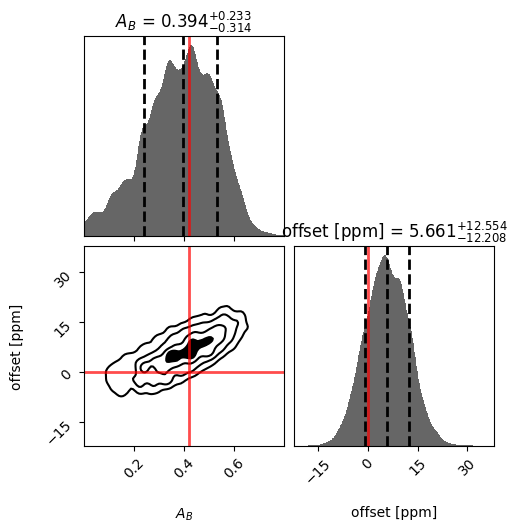

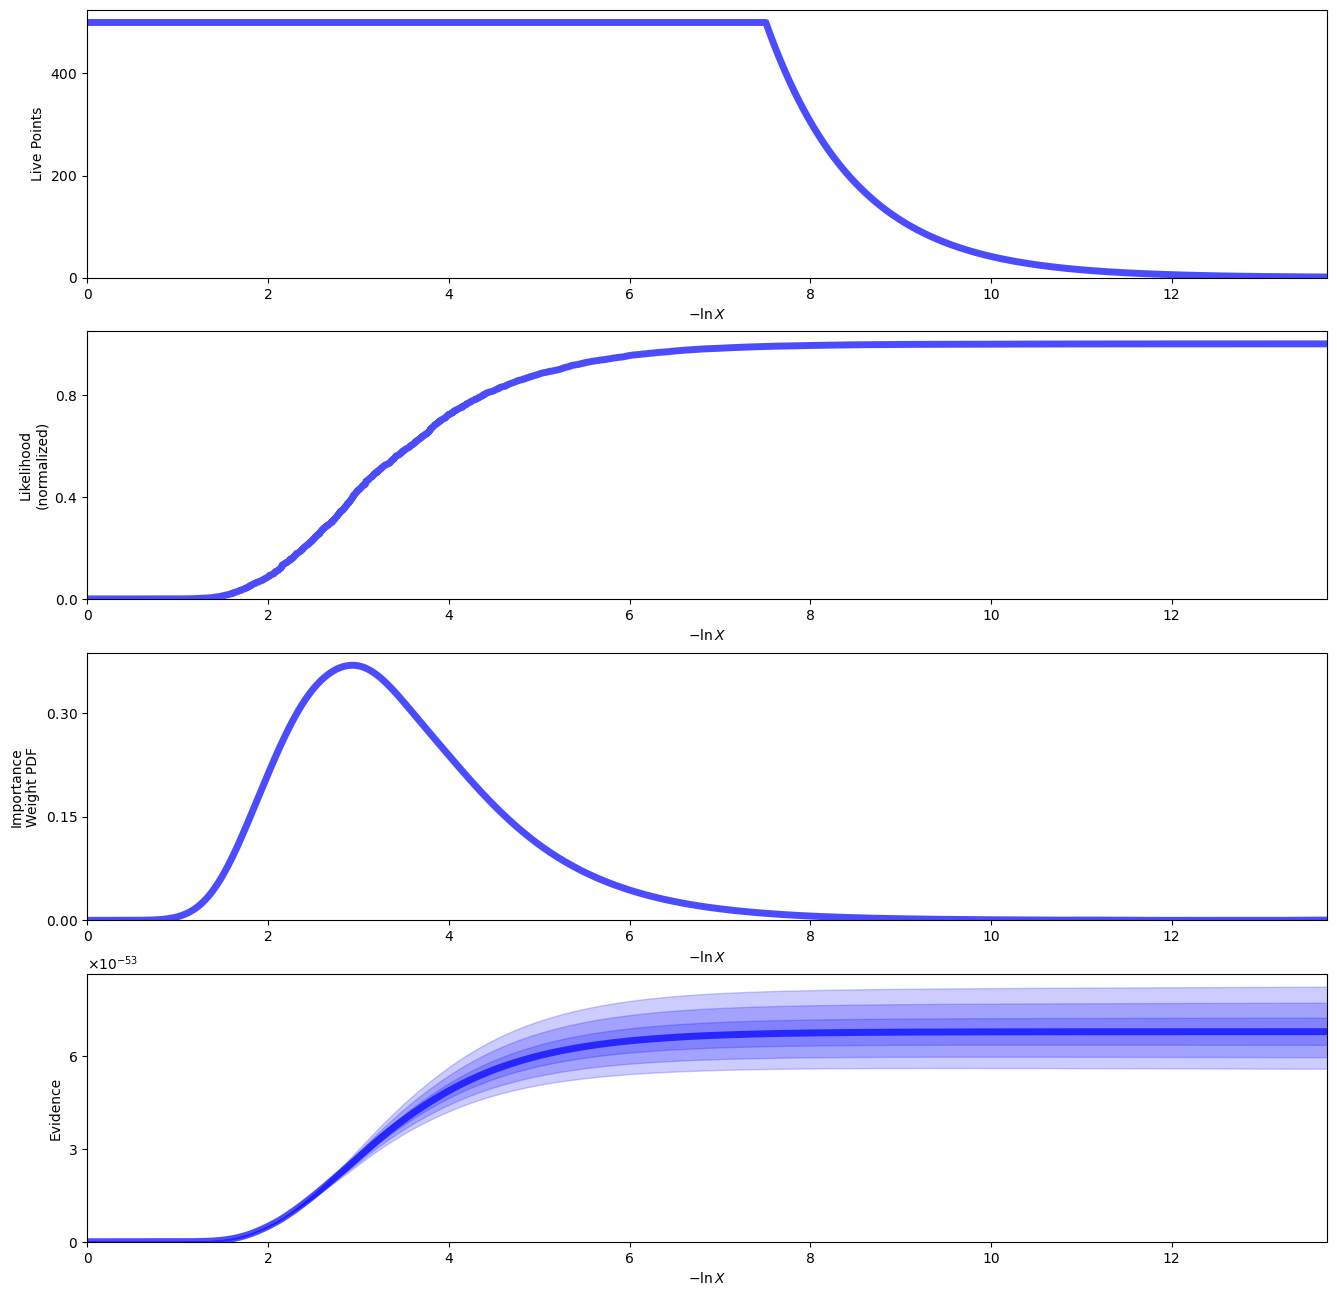

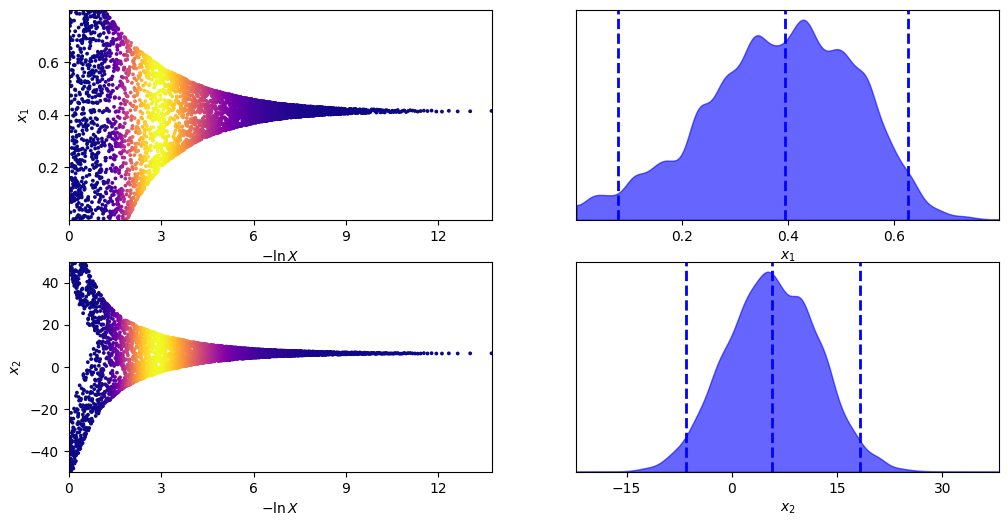

hyperillum   (ESS 1948, information 2.01 nats)
   A_B      =    0.4485 +0.1180 -0.1487   (mean 0.4359 +/- 0.1313, truth 0.42)
   offset   =    0.6423 +6.7934 -7.0030   (mean 0.5350 +/- 6.8688, truth 0)


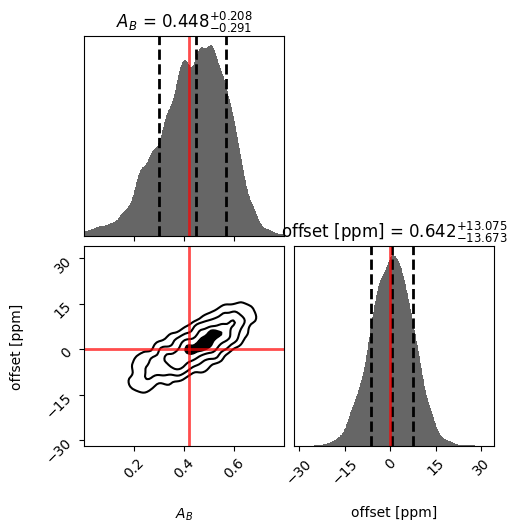

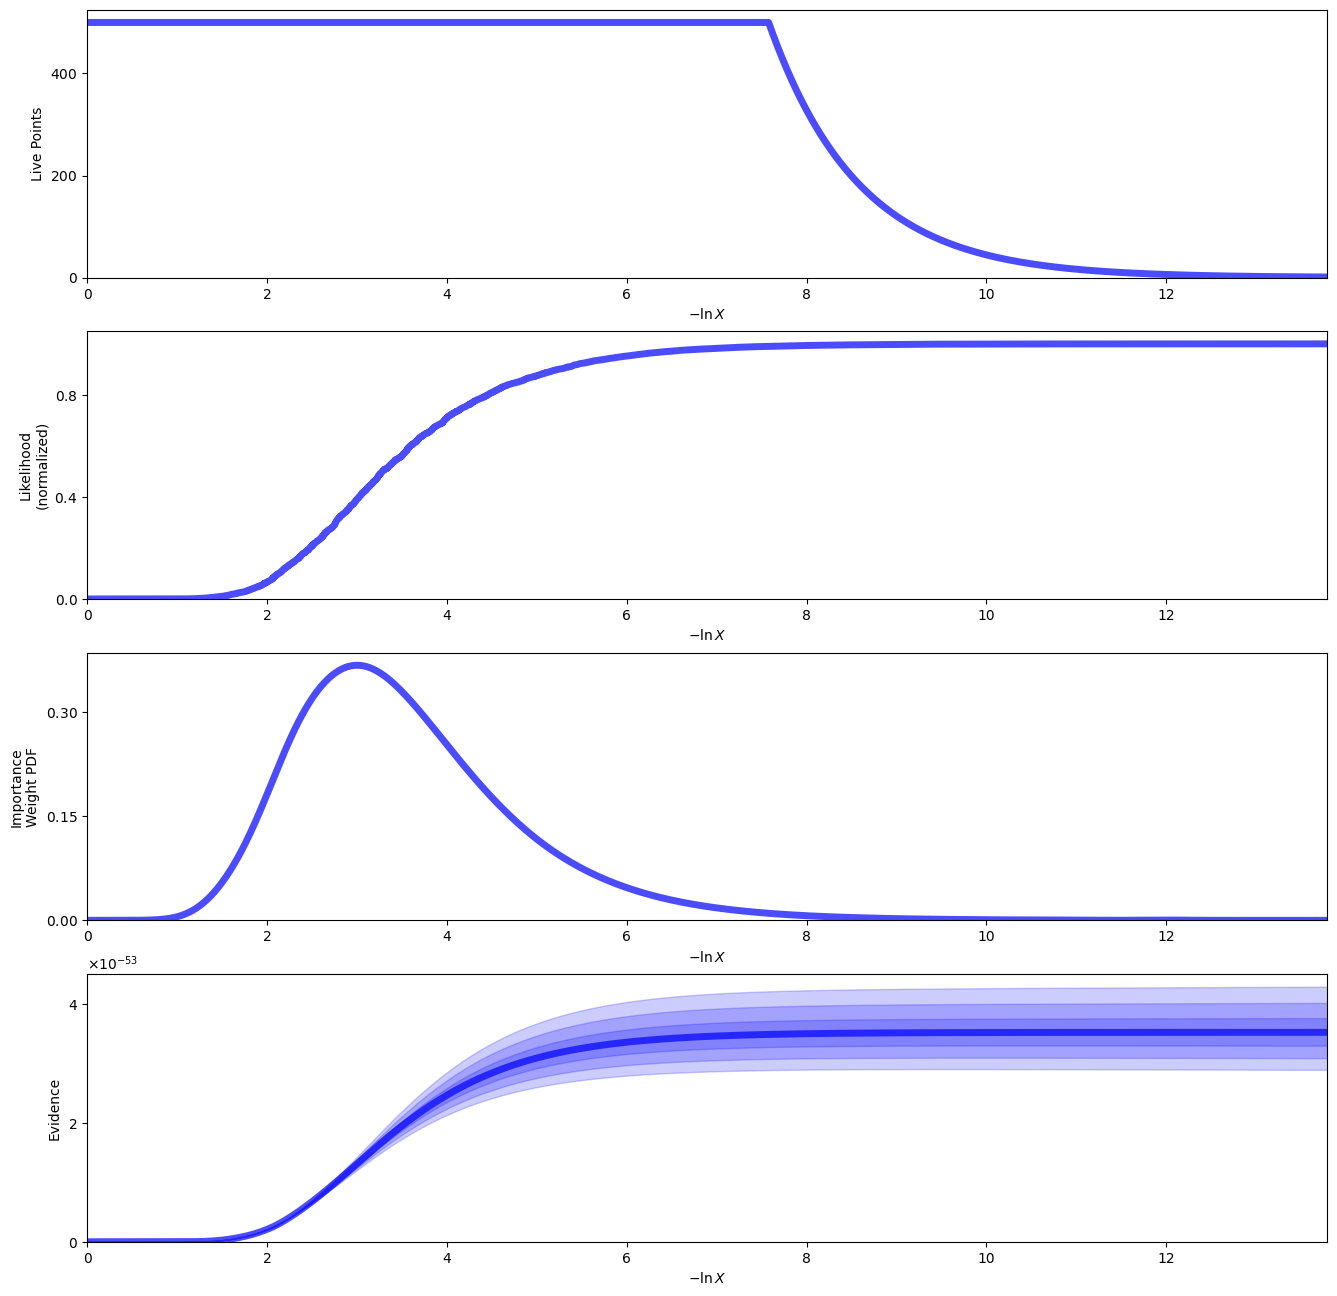

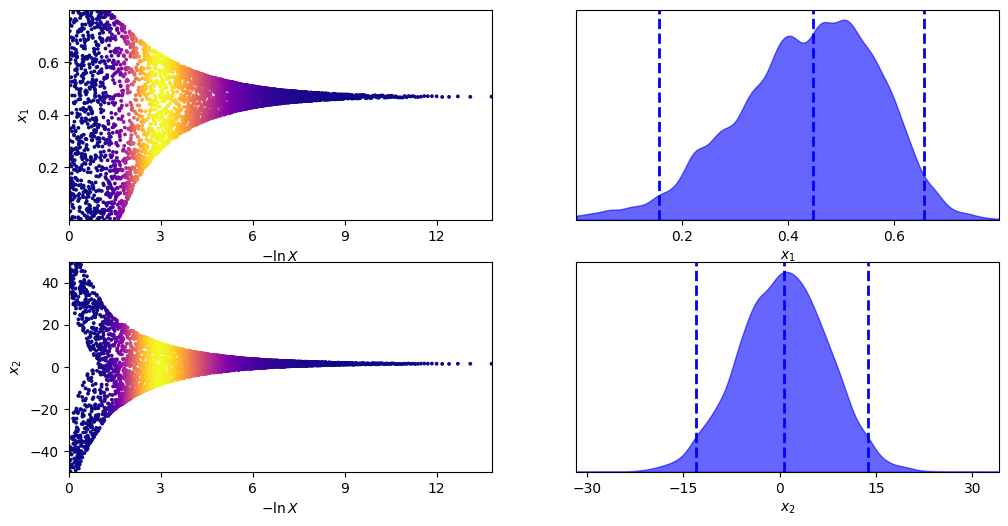

In [10]:
for name, fit in fits.items():
    # `res.samples` is NOT posterior-distributed: weight with `res.importance_weights()`, or take`res.samples_equal()` for plain draws.
    w = fit.results.importance_weights()
    mean, cov = dyfunc.mean_and_cov(fit.results.samples, w)
    print(f"{name}   (ESS {1./np.sum(w**2):.0f}, information {fit.meta['information']:.2f} nats)")
    for i, p in enumerate(pset.names):
        lo, med, hi = dyfunc.quantile(fit.results.samples[:, i], [0.16, 0.50, 0.84], weights=w)
        print(f"   {p:8s} = {med:9.4f} +{hi-med:.4f} -{med-lo:.4f}   (mean {mean[i]:.4f} +/- {np.sqrt(cov[i,i]):.4f}, truth {base[p]:g})")

    dyplot.cornerplot(fit.results, labels=list(pset.labels), truths=[base[p] for p in pset.names], show_titles=True, title_fmt=".3f", quantiles=[0.16, 0.5, 0.84])
    plt.show()
    dyplot.runplot(fit.results); plt.show()
    dyplot.traceplot(fit.results); plt.show()

## 4. Posterior comparison

Everything below reuses `fits`, `logls`, `pset`, `base`, `COLOR` and `lnL_maps` from above. 4.1-4.2 are pure post-processing of the two `Results` objects and cost **no** likelihood calls; 4.3-4.5 cost `N_DRAWS` forward models per insolation model.

### 4.1 Corner Plot

`res.samples` is ~uniform in $\ln X$, not posterior-distributed, so the density below is built from `res.samples_equal()`. Contours enclose 68% / 95% of the posterior *mass* (sort the cells by height, walk down until the mass is reached) - not Gaussian $\sigma$.

Dotted: the profile-likelihood contours from 2.2. With a uniform prior the likelihood map and the posterior differ only by the sampler's finite resolution, so a visible offset between dotted and filled contours is prior volume (Occam), not fit quality.

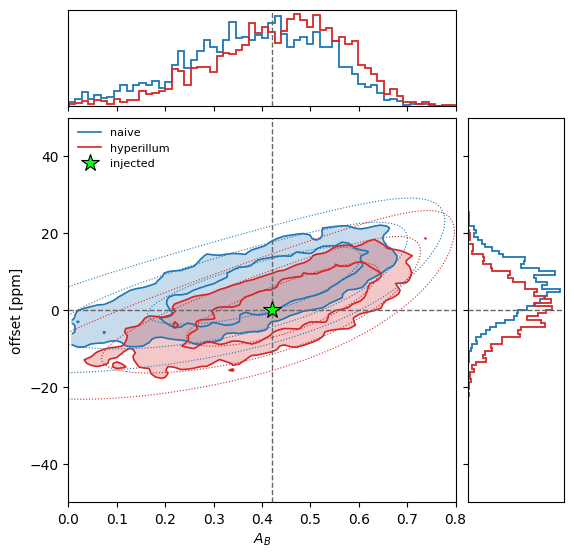

In [11]:
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
plt.show()

### 4.2 Bias, degeneracy and the Bayes factor

`bayes_factor` quotes two errors. The analytic one is dynesty's `logzerr` added in quadrature; the jitter one is the spread of `jitter_run` realisations, which resample the prior-volume shrinkage $t_i\sim\mathrm{Beta}(N,1)$ that nested sampling only knows statistically - it needs no Gaussian assumption about either $\ln Z$.

naive   ESS 1936, information 1.95 nats
   A_B      =    0.3937 +0.1368 -0.1552   truth 0.42, bias -0.0263 = -0.18 sigma
   offset   =    5.6613 +6.7825 -6.5300   truth 0, bias +5.6613 = +0.85 sigma
   corr(A_B, offset) = +0.727
hyperillum   ESS 1948, information 2.01 nats
   A_B      =    0.4485 +0.1180 -0.1487   truth 0.42, bias +0.0285 = +0.21 sigma
   offset   =    0.6423 +6.7934 -7.0030   truth 0, bias +0.6423 = +0.09 sigma
   corr(A_B, offset) = +0.778
ln B (hyperillum vs naive) = -0.656 +/- 0.092 (analytic) +/- 0.086 (jitter, K=200)  ->  B = 0.519
P(sign of ln B secure) = 0.000  [sampler noise only, NOT a model probability]


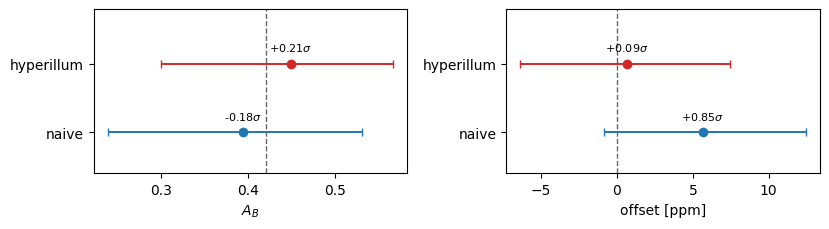

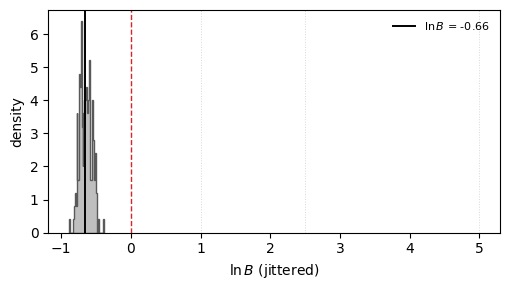

In [12]:
for f in fits.values(): posterior_summary(f, base)

# lnB: "does this dataset contain enough information to distinguish the two models?"
bf = bayes_factor(fits, "hyperillum", "naive", K=200)

plot_bias(fits, base, colors=COLOR); plt.show()
plot_evidence_jitter(bf); plt.show()

### 4.3 Posterior predictive - and where in phase the evidence comes from

Bottom panel: the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases.

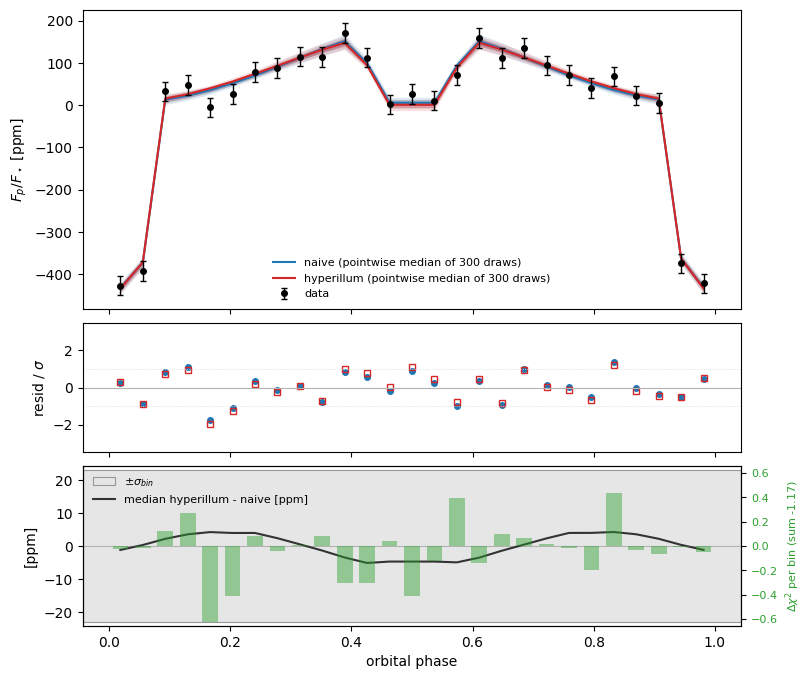

In [13]:
N_DRAWS = 300   # forward models per insolation model

plot_posterior_predictive(logls, fits, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.

### 4.4 Derived quantities

The $A_B$ posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model.
`T_term` > 0 for naive is an interpolation artefact: it is `np.interp` of the temperature grid at exactly 90°, between the last dayside and the first nightside node. The naive nightside itself (`T_anti`) is 0 K.

naive       occultation_depth  167.85 ppm
hyperillum  occultation_depth  168.77 ppm
naive       depth  174.6 +15.4 -16.1 ppm (thermal 169.8, reflected 4.8)   T_bright 2377.6 +143.9 -151.2 K
            T_sub 2671.8 K   T_term  539.5 K   T_anti   0.0 K
hyperillum  depth  168.8 +15.0 -12.6 ppm (thermal 164.0, reflected 4.8)   T_bright 2322.8 +139.8 -118.8 K
            T_sub 2612.2 K   T_term 1415.9 K   T_anti   0.0 K


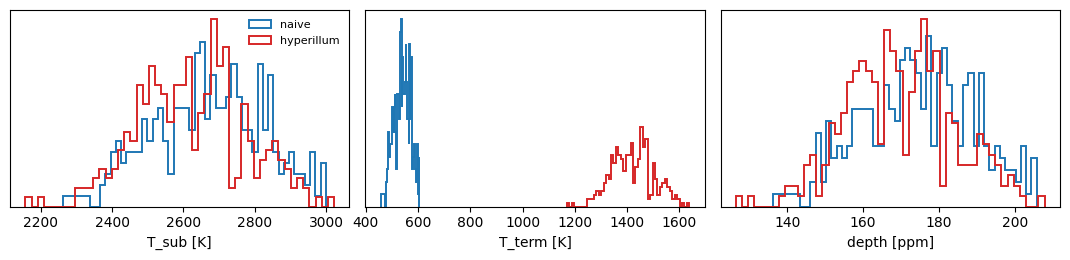

In [14]:
# Check on the factored-out pcurve_params: for a thermal-only, transit-free config the occultation depth must match the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    _, y_ = model_pcurve(cfg_th, m, A_B_true, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true), stellar_grid=cfg.stellar_grid)
    print(f"{m:11s} occultation_depth {d_:7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:11s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    print(f"{'':11s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {np.median(d['T_anti']):5.1f} K")

plot_derived(der, keys=("T_sub", "T_term", "depth"), colors=COLOR); plt.show()

### 4.5 Noisy fit vs. the noiseless truth
Overlaid on the §1 truth:

- the two dynesty **posterior medians** - what you would report from this one dataset, noise and all
- the naive model fitted to the **noiseless** binned truth (`simple_bias_analysis.fit_naive`, offset free) - deterministic, no seed. **This is the bias.**
- the truth itself, the curve the data were drawn from

Lower panel: everything minus the binned truth, against $\pm\sigma_{\rm bin}$. Black points are the data, i.e. the noise the two medians are chasing. The dotted grey line is the numerical floor - the *same* model at the *same* parameters, evaluated on the likelihood's coarser grid instead of the truth's. It should sit on zero; whatever it does is grid resolution, not physics, and it bounds how much of this figure can be believed.

naive       median   A_B 0.3937 (-0.0263 = -0.18 sigma)   offset   +5.66 ppm (+5.66 = +0.85 sigma)   chi2 vs truth   0.66   vs data  15.36
            max-lnL  A_B 0.4138 (-0.0062)              offset   +6.37 ppm (+6.37)           chi2 vs truth   0.71   vs data  15.35
hyperillum  median   A_B 0.4485 (+0.0285 = +0.21 sigma)   offset   +0.64 ppm (+0.64 = +0.09 sigma)   chi2 vs truth   0.10   vs data  16.54
            max-lnL  A_B 0.4681 (+0.0481)              offset   +1.45 ppm (+1.45)           chi2 vs truth   0.18   vs data  16.52

NOISELESS naive vs the NOISELESS truth  (offset free, no noise, no seed - this is THE bias):
   A_B      0.3766   bias -0.0434 = -0.30 sigma_post   ->   dT/T = +1.82 %
   offset absorbed +5.75 ppm    chi2 0.582  (squared truth-to-manifold distance in units of sigma_bin)    resid rms 3.39 ppm = 0.15 sigma_bin
   the noisy naive median instead says -0.0263; the gap to -0.0434 is this one seed's noise (sigma_A_B = 0.1460)

numerical floor: hyperillum at the in

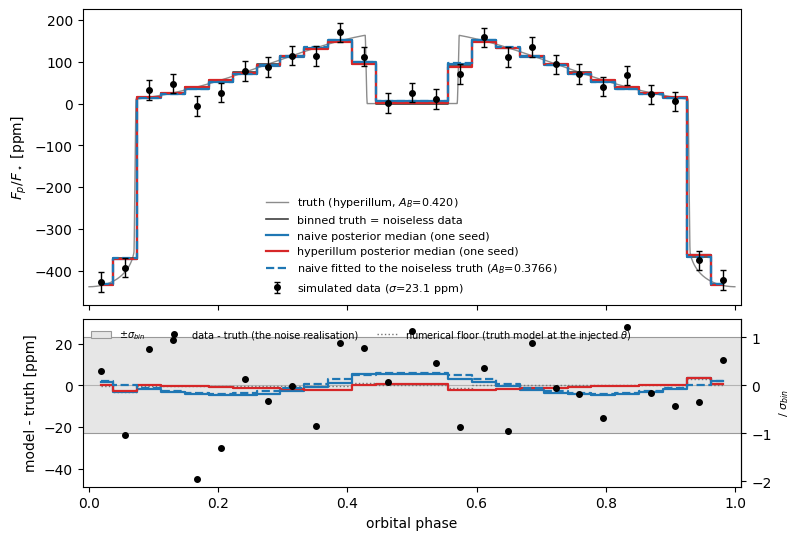

In [15]:
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH, A_B_bounds=A_B_BOUNDS, colors=COLOR)
plt.show()